In [20]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

os.makedirs("eda_outputs", exist_ok=True)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 160)

df = pd.read_csv("../data/raw/synthetic_projects.csv")

In [21]:
print("="*60)
print("1. BASIC STRUCTURE")
print("="*60)
print("Shape:", df.shape)
print("\nDtypes:\n", df.dtypes)
print("\nFirst 5 rows:\n", df.head())

1. BASIC STRUCTURE
Shape: (3000, 19)

Dtypes:
 project_id                        str
project_name                      str
project_type                      str
state                             str
district                          str
land_area_hectares            float64
affected_families               int64
compensation_disbursed_pct    float64
active_legal_disputes           int64
possession_pct                float64
rnr_progress_pct              float64
stakeholder_responsiveness    float64
dept_historical_delay_rate    float64
days_since_notification         int64
planned_completion_days         int64
true_risk_debug               float64
is_delayed                      int64
delay_days                      int64
actual_completion_days          int64
dtype: object

First 5 rows:
     project_id                project_name      project_type      state         district  land_area_hectares  affected_families  compensation_disbursed_pct  \
0  LA-OD-00000  Irrigation Canal Project 0

Data Quality Checks

In [22]:
print("\n" + "="*60)
print("2. DATA QUALITY")
print("="*60)
print("Missing values per column:\n", df.isna().sum())
print("\nDuplicate rows:", df.duplicated().sum())
print("Duplicate project_id:", df["project_id"].duplicated().sum())


2. DATA QUALITY
Missing values per column:
 project_id                    0
project_name                  0
project_type                  0
state                         0
district                      0
land_area_hectares            0
affected_families             0
compensation_disbursed_pct    0
active_legal_disputes         0
possession_pct                0
rnr_progress_pct              0
stakeholder_responsiveness    0
dept_historical_delay_rate    0
days_since_notification       0
planned_completion_days       0
true_risk_debug               0
is_delayed                    0
delay_days                    0
actual_completion_days        0
dtype: int64

Duplicate rows: 0
Duplicate project_id: 0


Statistical Summary

In [23]:
print("\n" + "="*60)
print("3. NUMERIC SUMMARY")
print("="*60)
print(df.describe().T)

print("\nCategorical value counts:")
for col in ["project_type", "state"]:
    print(f"\n--{col}--\n", df[col].value_counts())


3. NUMERIC SUMMARY
                             count        mean         std     min      25%     50%      75%      max
land_area_hectares          3000.0   75.515800   59.171679    5.00   37.175   58.25   94.125   400.00
affected_families           3000.0  177.869000  116.839809   20.00  101.000  148.00  220.250  1098.00
compensation_disbursed_pct  3000.0   41.963833   19.923722    1.30   26.500   40.30   56.700    96.80
active_legal_disputes       3000.0    1.299000    1.157603    0.00    0.000    1.00    2.000     6.00
possession_pct              3000.0   50.043567   23.342248    5.00   30.375   50.00   69.500    95.00
rnr_progress_pct            3000.0   27.091167   21.244572    3.00    5.300   24.30   43.600    80.60
stakeholder_responsiveness  3000.0    0.390470    0.231332    0.05    0.180    0.39    0.590     0.87
dept_historical_delay_rate  3000.0    0.585630    0.137241    0.13    0.490    0.60    0.690     0.95
days_since_notification     3000.0  213.590333  106.612153   3

Target Balance

In [24]:
print("\n" + "="*60)
print("4. TARGET BALANCE")
print("="*60)
print(df["is_delayed"].value_counts(normalize=True))


4. TARGET BALANCE
is_delayed
0    0.621
1    0.379
Name: proportion, dtype: float64


Outlier Check

In [25]:
print(df.columns.tolist())

['project_id', 'project_name', 'project_type', 'state', 'district', 'land_area_hectares', 'affected_families', 'compensation_disbursed_pct', 'active_legal_disputes', 'possession_pct', 'rnr_progress_pct', 'stakeholder_responsiveness', 'dept_historical_delay_rate', 'days_since_notification', 'planned_completion_days', 'true_risk_debug', 'is_delayed', 'delay_days', 'actual_completion_days']


In [26]:
# Rule: only check columns that are (a) numeric, (b) continuous/unbounded
# (not 0-100 percentages or 0-1 scores, since extreme values there are
# still "valid" within their fixed range), and (c) have wide enough range
# for IQR to be meaningful (not small-range counts like legal disputes).

print("\n" + "="*60)
print("5. OUTLIER CHECK (IQR method, unbounded numeric columns only)")
print("="*60)
unbounded_cols = ["land_area_hectares", "affected_families",
                   "days_since_notification", "planned_completion_days"]
for col in unbounded_cols:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = ((df[col] < lower) | (df[col] > upper)).sum()
    print(f"{col}: bounds=[{lower:.1f}, {upper:.1f}]  outliers={n_out} ({n_out/len(df):.1%})")


5. OUTLIER CHECK (IQR method, unbounded numeric columns only)
land_area_hectares: bounds=[-48.2, 179.6]  outliers=172 (5.7%)
affected_families: bounds=[-77.9, 399.1]  outliers=152 (5.1%)
days_since_notification: bounds=[-153.1, 579.9]  outliers=0 (0.0%)
planned_completion_days: bounds=[-2.1, 722.9]  outliers=0 (0.0%)


Distribution Plots

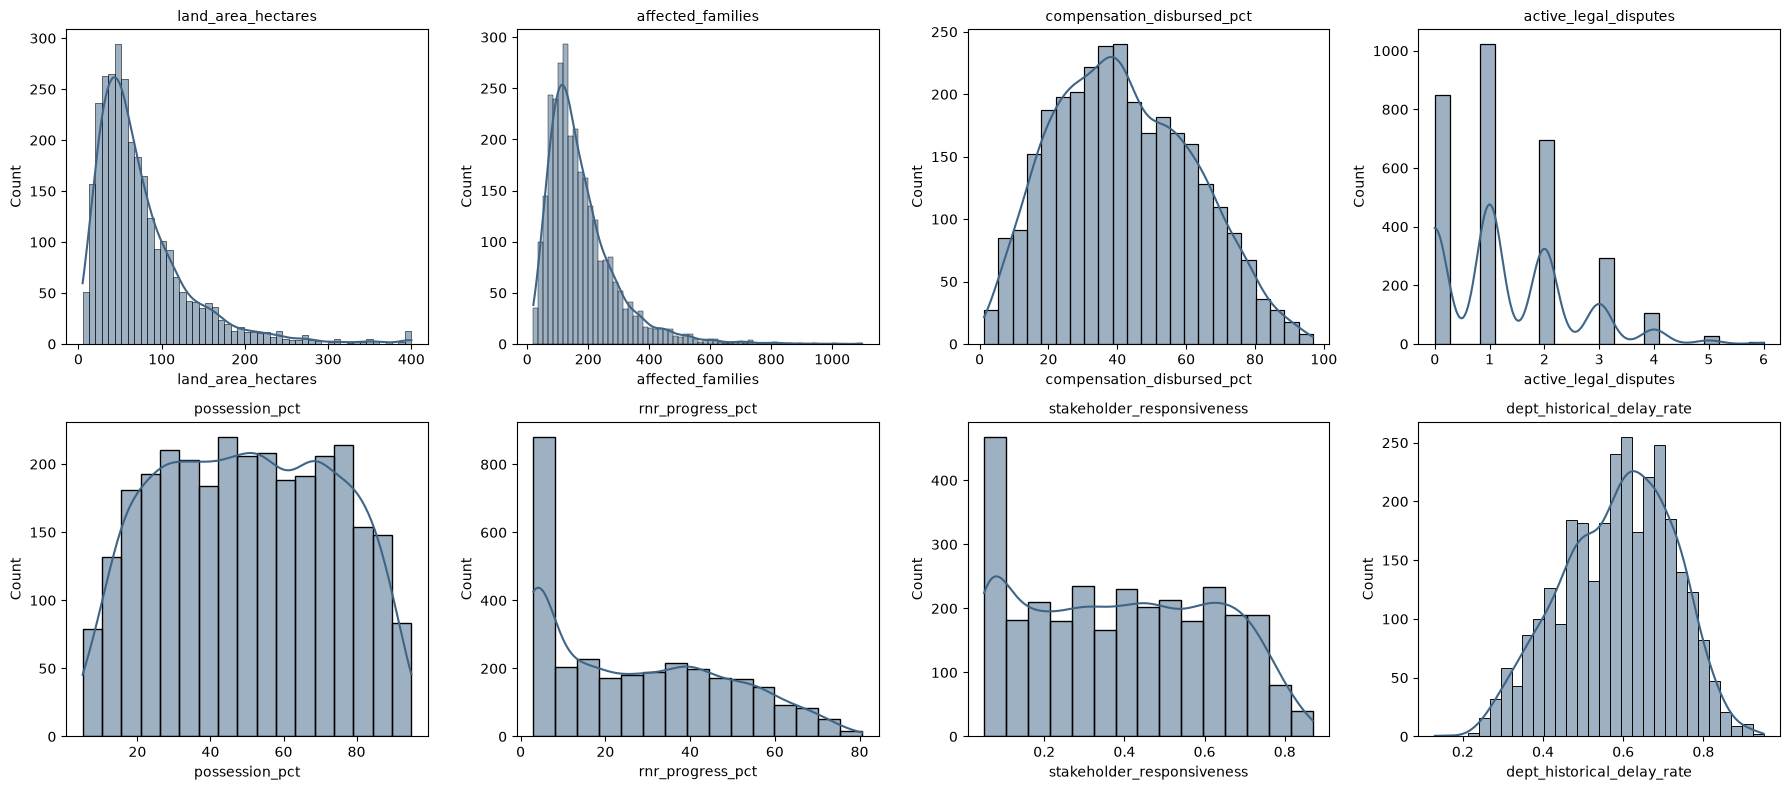

In [27]:
numeric_cols = ["land_area_hectares", "affected_families", "compensation_disbursed_pct",
                 "active_legal_disputes", "possession_pct", "rnr_progress_pct",
                 "stakeholder_responsiveness", "dept_historical_delay_rate"]

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.flatten(), numeric_cols):
    sns.histplot(df[col], kde=True, ax=ax, color="#3E6486")
    ax.set_title(col, fontsize=10)
plt.tight_layout()
plt.savefig("eda_outputs/distributions.png", dpi=110)
plt.show()

Correlation Heatmap

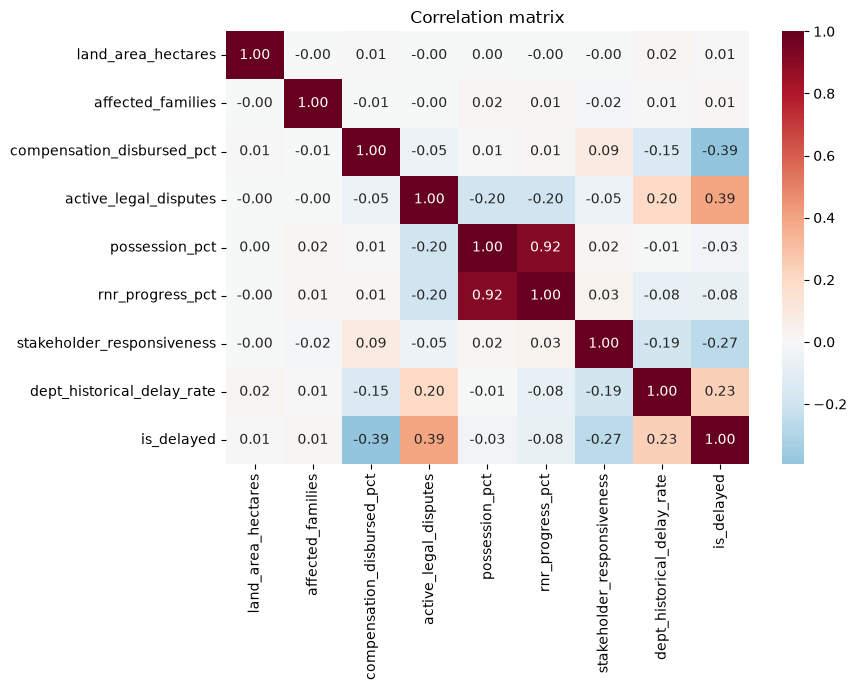

In [28]:
corr_cols = numeric_cols + ["is_delayed"]
plt.figure(figsize=(9, 7))
sns.heatmap(df[corr_cols].corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0)
plt.title("Correlation matrix")
plt.tight_layout()
plt.savefig("eda_outputs/correlation.png", dpi=110)
plt.show()

Target-wise Boxplot

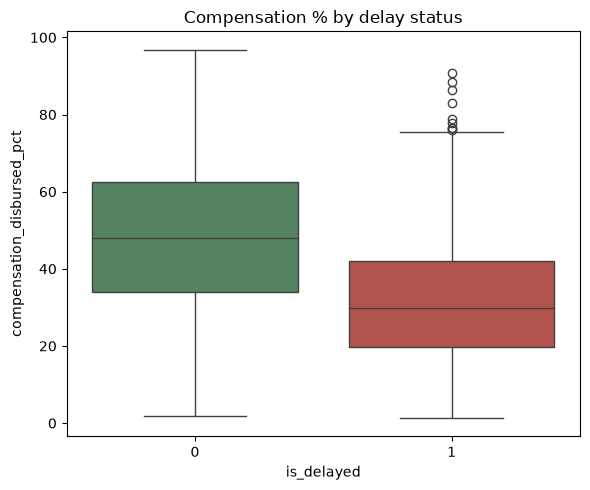

In [29]:
plt.figure(figsize=(6, 5))
sns.boxplot(data=df, x="is_delayed", y="compensation_disbursed_pct",
            hue="is_delayed", palette={0: "#4C8B5D", 1: "#C1443C"}, legend=False)
plt.title("Compensation % by delay status")
plt.tight_layout()
plt.savefig("eda_outputs/compensation_by_delay.png", dpi=110)
plt.show()

In [ ]:
python -m pip install --upgrade pip

In [ ]:
pip install ydata-profiling

In [ ]:
# from ydata_profiling import ProfileReport

# df = pd.read_csv("data/raw/synthetic_projects_v1.csv")

# profile = ProfileReport(df, title="Land Acquisition Dataset — Profiling Report", explorative=True)
# profile.to_file("eda_outputs/profiling_report.html")

ModuleNotFoundError: No module named 'ydata_profiling'